# Bonus A/B Test & ROI Analysis — iGaming (Polars)

This notebook is a thin, readable wrapper around the `bonus_ab_test` package (see `src/bonus_ab_test/`). All the real logic — funnel aggregation, significance testing, ROI, segmentation — lives in tested, importable modules; this notebook just calls it and shows the results inline.

Run `pip install -e ".[dev]"` from the repo root first so `bonus_ab_test` is importable.

In [1]:
import polars as pl

from bonus_ab_test.config import SimulationConfig
from bonus_ab_test.simulate import simulate_players
from bonus_ab_test.funnel import funnel_by_group, segment_lift
from bonus_ab_test.stats_tests import two_proportion_ztest, welch_ttest
from bonus_ab_test.roi import compute_roi
from bonus_ab_test import viz

## 0. Load or simulate data

If `data/ab_test_players.parquet` already exists (generated via the CLI: `bonus-ab-test simulate`), just load it. Otherwise simulate a smaller sample inline for a quick run.

In [2]:
from pathlib import Path

data_path = Path("../data/ab_test_players.parquet")
if data_path.exists():
    df = pl.read_parquet(data_path)
else:
    df = simulate_players(SimulationConfig(n_players=200_000))

print(f"{df.height:,} rows x {df.width} cols")
df.head()

3,000,000 rows x 14 cols


player_id,country,device,channel,vertical,group,reached_deposit,first_deposit_amount,reached_bet,repeat_deposit_30d,repeat_deposit_amount,bonus_cost,ltv_30d,signup_date
i64,str,str,str,str,str,bool,f64,bool,bool,f64,f64,f64,date
1,"""PH""","""desktop""","""organic""","""casino""","""treatment""",true,41.8,true,true,24.41,41.8,66.21,2025-01-09
2,"""BR""","""mobile""","""paid_social""","""casino""","""treatment""",false,0.0,false,false,0.0,0.0,0.0,2025-03-11
3,"""BR""","""desktop""","""paid_social""","""sportsbook""","""control""",false,0.0,false,false,0.0,0.0,0.0,2025-02-28
4,"""CA""","""mobile""","""affiliate""","""casino""","""treatment""",false,0.0,false,false,0.0,0.0,0.0,2025-02-09
5,"""NG""","""desktop""","""paid_social""","""casino""","""treatment""",false,0.0,false,false,0.0,0.0,0.0,2025-02-08


## 1. Funnel by group

In [3]:
funnel = funnel_by_group(df)
funnel

group,signups,deposits,bets,repeat_deposits,avg_first_deposit,total_bonus_cost,total_ltv_30d,signup_to_deposit_rate,deposit_to_bet_rate,repeat_deposit_rate
str,u32,u32,u32,u32,f64,f64,f64,f64,f64,f64
"""control""",1499012,544129,473689,159658,45.005169,0.0,2.8386e7,0.362992,0.870545,0.293419
"""treatment""",1500988,612024,538863,213178,52.038934,2.3851e7,3.7053e7,0.407747,0.880461,0.348316


In [4]:
ctrl = funnel.filter(pl.col("group") == "control").row(0, named=True)
trt = funnel.filter(pl.col("group") == "treatment").row(0, named=True)

## 2. Statistical significance

In [5]:
deposit_test = two_proportion_ztest(ctrl["deposits"], ctrl["signups"], trt["deposits"], trt["signups"])
print(f"Signup -> Deposit: control={deposit_test.p_control:.4%}, treatment={deposit_test.p_treatment:.4%}")
print(f"Lift: {deposit_test.absolute_lift:+.4%}  p-value: {deposit_test.p_value:.2e}  significant: {deposit_test.significant}")

Signup -> Deposit: control=36.2992%, treatment=40.7747%
Lift: +4.4756%  p-value: 0.00e+00  significant: True


In [6]:
repeat_test = two_proportion_ztest(ctrl["repeat_deposits"], ctrl["deposits"], trt["repeat_deposits"], trt["deposits"])
print(f"Repeat deposit (30d): control={repeat_test.p_control:.4%}, treatment={repeat_test.p_treatment:.4%}")
print(f"Lift: {repeat_test.absolute_lift:+.4%}  p-value: {repeat_test.p_value:.2e}  significant: {repeat_test.significant}")

Repeat deposit (30d): control=29.3419%, treatment=34.8316%
Lift: +5.4897%  p-value: 0.00e+00  significant: True


In [7]:
ctrl_amt = df.filter((pl.col("group") == "control") & pl.col("reached_deposit"))["first_deposit_amount"].to_numpy()
trt_amt = df.filter((pl.col("group") == "treatment") & pl.col("reached_deposit"))["first_deposit_amount"].to_numpy()
amount_test = welch_ttest(trt_amt, ctrl_amt)
print(f"First deposit amount: control=${amount_test.mean_control:.2f}, treatment=${amount_test.mean_treatment:.2f}")
print(f"Difference: ${amount_test.difference:+.2f}  p-value: {amount_test.p_value:.2e}  significant: {amount_test.significant}")

First deposit amount: control=$45.01, treatment=$52.04
Difference: $+7.03  p-value: 0.00e+00  significant: True


## 3. Bonus ROI

In [8]:
roi_result = compute_roi(
    control_total_volume=ctrl["total_ltv_30d"],
    control_signups=ctrl["signups"],
    treatment_total_volume=trt["total_ltv_30d"],
    treatment_signups=trt["signups"],
    treatment_total_bonus_cost=trt["total_bonus_cost"],
)
print(f"Bonus cost: ${roi_result.total_bonus_cost:,.2f}")
print(f"Incremental 30d volume: ${roi_result.incremental_volume:,.2f}")
print(f"ROI: {roi_result.roi:.2f}x")
print()
print(roi_result.recommendation(significant_lift=deposit_test.significant and repeat_test.significant))

Bonus cost: $23,851,495.03
Incremental 30d volume: $8,629,463.78
ROI: 0.36x

DO NOT ROLL OUT AS BLANKET OFFER: lift is significant but bonus cost exceeds incremental volume. Consider targeting only high-lift segments or lowering the match cap.


## 4. Segmentation

In [9]:
segment_lift(df, "country")

country,treatment,control,lift_pp
str,f64,f64,f64
"""CA""",0.435707,0.389367,0.04634
"""NG""",0.39674,0.350992,0.045748
"""IN""",0.40477,0.359546,0.045224
"""BR""",0.424806,0.379744,0.045062
"""ZA""",0.414522,0.369904,0.044618
"""PH""",0.39413,0.349895,0.044236
"""DE""",0.383761,0.339737,0.044024
"""MX""",0.404232,0.361248,0.042984


In [10]:
segment_lift(df, "device")

device,treatment,control,lift_pp
str,f64,f64,f64
"""mobile""",0.413601,0.368672,0.044929
"""desktop""",0.392733,0.348366,0.044367


## 5. Charts

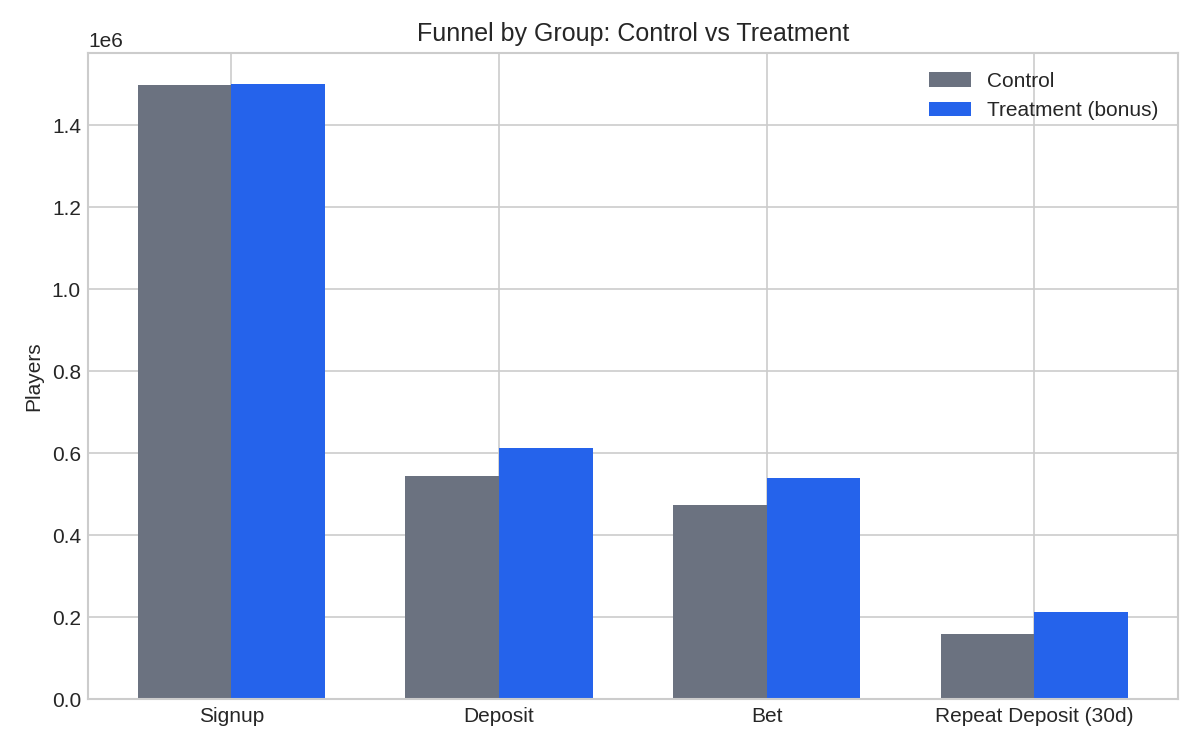

In [11]:
import matplotlib.pyplot as plt
from IPython.display import Image

path = viz.plot_funnel_comparison(funnel, "funnel_comparison.png")
Image(filename=str(path))

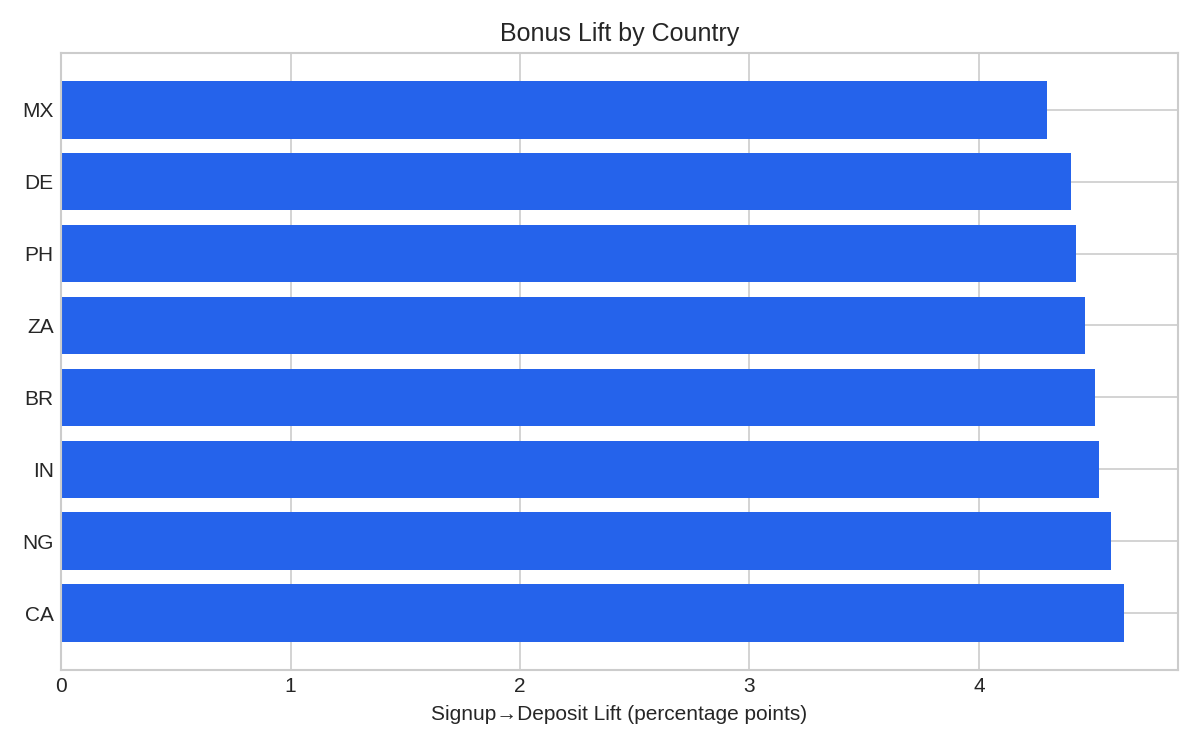

In [12]:
seg_country = segment_lift(df, "country")
path = viz.plot_segment_lift(seg_country, "country", "Bonus Lift by Country", "lift_by_country.png")
Image(filename=str(path))